In [1]:
!pip install deepface opencv-python-headless tf-keras transformers pillow torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.7/170.7 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 38.7 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.3/51.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 56.3 MB/s eta 0:00:00


In [2]:
"""
Three-classifier bias detection: CLIP + FairFace + DeepFace, on the full
fragmented T2I dataset. Same architecture as before: reads images in place
(no merge/copy), persists results to a Kaggle dataset, resumable, push
safety check.

WHAT EACH CLASSIFIER PROVIDES (gender is common to all three for comparison):
- DeepFace : gender, age, race, emotion   (one .analyze() call, all at once)
- FairFace : gender, age                    (dima806 HF models; no race model exists)
- CLIP     : gender, race, age             (zero-shot, via text-prompt matching)

All three run on each image so you can (a) report bias per attribute and
(b) measure inter-classifier agreement / decide which detector is most
reliable against a hand-labelled sample later.

Gender is normalized to Man/Woman across all three so the columns are
directly comparable. Race label sets differ between DeepFace and CLIP --
they're kept in separate columns, not force-merged, since their taxonomies
aren't identical.

ETHICAL NOTE (put this in your paper): these are PERCEIVED / visual
attribute estimates from appearance, not ground-truth identity. Race
classification especially is contested and unreliable, and overlaps
confusingly with your nationality/religion modifiers -- report it with
heavy caveats or as secondary.

ONE-TIME SETUP:
  !pip install deepface opencv-python-headless tf-keras transformers pillow torch
  Create a NEW empty Kaggle dataset for these results, add it as Input,
  confirm its exact mount path via os.listdir("/kaggle/input"), set
  RESULTS_MOUNT below to match.
"""

import os
import csv
import json
import subprocess
import shutil
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import torch
from PIL import Image
from deepface import DeepFace
from transformers import pipeline, CLIPProcessor, CLIPModel

# ---------------- CONFIG ----------------
INPUT_ROOT    = "/kaggle/input"
MODEL_NAMES   = ["kandinsky22", "pixart_sigma", "sd1.5", "sdxl_turbo"]

RESULTS_DATASET_SLUG = "ajfaisal002/three-classifier-bias-results"   # CREATE THIS DATASET FIRST (empty)
RESULTS_MOUNT         = "/kaggle/input/three-classifier-bias-results"  # VERIFY via os.listdir("/kaggle/input")

RESULTS_CSV   = "/kaggle/working/three_classifier_bias_results.csv"
DETECTOR      = "retinaface"    # used by DeepFace, and to crop faces for FairFace
FLUSH_EVERY   = 100
PRINT_EVERY   = 50
DEVICE        = "cuda" if torch.cuda.is_available() else "cpu"
_HF_DEVICE    = 0 if DEVICE == "cuda" else -1

FIELDNAMES = [
    "model", "profession", "category", "modifier", "prompt_id", "image_file",
    "face_detected",
    # DeepFace
    "df_gender", "df_age", "df_race", "df_emotion",
    # FairFace
    "ff_gender", "ff_gender_score", "ff_age", "ff_age_score",
    # CLIP (zero-shot)
    "clip_gender", "clip_gender_score", "clip_race", "clip_race_score", "clip_age", "clip_age_score",
    # agreement on gender across all three
    "gender_all_agree",
    "error"
]

# ---------------- LOAD MODELS ONCE ----------------
print("Loading FairFace models (gender, age)...")
ff_gender = pipeline("image-classification", model="dima806/fairface_gender_image_detection", device=_HF_DEVICE)
ff_age    = pipeline("image-classification", model="dima806/fairface_age_image_detection", device=_HF_DEVICE)

print("Loading CLIP...")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
clip_proc  = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# CLIP zero-shot label sets (text prompts it compares the image against)
CLIP_GENDER = {"a photo of a man": "Man", "a photo of a woman": "Woman"}
CLIP_RACE = {
    "a photo of a White person": "White",
    "a photo of a Black person": "Black",
    "a photo of an East Asian person": "East Asian",
    "a photo of a South Asian person": "South Asian",
    "a photo of a Middle Eastern person": "Middle Eastern",
    "a photo of a Latino Hispanic person": "Latino_Hispanic",
    "a photo of a Southeast Asian person": "Southeast Asian",
}
CLIP_AGE = {
    "a photo of a child": "child",
    "a photo of a young adult": "young adult",
    "a photo of a middle-aged person": "middle-aged",
    "a photo of an elderly person": "elderly",
}

def clip_classify(pil_img, label_map):
    prompts = list(label_map.keys())
    inputs = clip_proc(text=prompts, images=pil_img, return_tensors="pt", padding=True).to(DEVICE)
    with torch.no_grad():
        out = clip_model(**inputs)
    probs = out.logits_per_image.softmax(dim=1)[0]
    best_idx = int(probs.argmax())
    return label_map[prompts[best_idx]], float(probs[best_idx])

def normalize_gender(label):
    l = str(label).strip().lower()
    if l in ("male", "man"):   return "Man"
    if l in ("female", "woman"): return "Woman"
    return label

def top_pred(pipe_out):
    top = max(pipe_out, key=lambda r: r["score"])
    return top["label"], top["score"]

# ---------------- RESTORE FROM PERSISTENT DATASET ----------------
def restore_results_csv():
    if os.path.exists(RESULTS_CSV):
        return 0
    src = os.path.join(RESULTS_MOUNT, os.path.basename(RESULTS_CSV))
    if os.path.isdir(RESULTS_MOUNT) and os.path.isfile(src):
        shutil.copy2(src, RESULTS_CSV)
        with open(RESULTS_CSV, newline="") as f:
            n = sum(1 for _ in csv.DictReader(f))
        print(f"Restored previous results from {src} ({n} rows)")
        return n
    else:
        print(f"No previous results found at {RESULTS_MOUNT} -- starting fresh.")
        with open(RESULTS_CSV, "w", newline="") as f:
            csv.DictWriter(f, fieldnames=FIELDNAMES).writeheader()
        return 0

_BASELINE_ROW_COUNT = restore_results_csv()

def push_results_to_dataset(message="checkpoint"):
    with open(RESULTS_CSV, newline="") as f:
        current = sum(1 for _ in csv.DictReader(f))
    if current < _BASELINE_ROW_COUNT:
        print(f"[SAFETY] PUSH BLOCKED: local ({current}) < persisted ({_BASELINE_ROW_COUNT}). Not pushing.")
        return
    out_dir = "/kaggle/working/results_push_three"
    os.makedirs(out_dir, exist_ok=True)
    shutil.copy2(RESULTS_CSV, os.path.join(out_dir, os.path.basename(RESULTS_CSV)))
    with open(os.path.join(out_dir, "dataset-metadata.json"), "w") as f:
        json.dump({"title": RESULTS_DATASET_SLUG.split("/")[-1], "id": RESULTS_DATASET_SLUG,
                   "licenses": [{"name": "CC0-1.0"}]}, f)
    result = subprocess.run(["kaggle", "datasets", "version", "-p", out_dir, "-m", message],
                            capture_output=True, text=True)
    if result.returncode != 0:
        result = subprocess.run(["kaggle", "datasets", "create", "-p", out_dir],
                                capture_output=True, text=True)
    if result.returncode == 0:
        print(f"[checkpoint] results pushed to {RESULTS_DATASET_SLUG}")
    else:
        print(f"[checkpoint] push FAILED (will retry).\nSTDOUT: {result.stdout}\nSTDERR: {result.stderr}")

# ---------------- RESUME ----------------
processed = set()
with open(RESULTS_CSV, newline="") as f:
    for row in csv.DictReader(f):
        processed.add(row["image_file"])
print(f"Resuming: {len(processed)} images already processed, will skip these.")

def parse_image_path(model_root, image_path):
    rel = os.path.relpath(image_path, model_root)
    parts = rel.split(os.sep)
    if len(parts) == 4:
        profession, category, prompt_folder, _img = parts
        modifier = ""
    elif len(parts) == 5:
        profession, category, modifier, prompt_folder, _img = parts
    else:
        return None
    return profession, category, modifier, prompt_folder.replace("prompt_", "")

def crop_face(image_path):
    try:
        faces = DeepFace.extract_faces(img_path=image_path, detector_backend=DETECTOR,
                                       enforce_detection=True, align=True)
        if not faces:
            return None
        best = max(faces, key=lambda fo: fo["facial_area"]["w"] * fo["facial_area"]["h"])
        return Image.fromarray((best["face"] * 255).astype(np.uint8)).convert("RGB")
    except ValueError:
        return None

# ---------------- MAIN LOOP ----------------
buffer = []
total_done = 0
seen_labels = set()

print("Scanning /kaggle/input for model folders (reading in place, no copying)...")

for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
    base = os.path.basename(dirpath)
    if base not in MODEL_NAMES:
        continue
    model_name = base
    model_root = dirpath
    print(f"[found] {model_name} at: {model_root}")

    for sub_dirpath, _sd, sub_filenames in os.walk(model_root):
        for fname in sub_filenames:
            if not fname.lower().endswith((".png", ".jpg", ".jpeg")):
                continue
            image_path = os.path.join(sub_dirpath, fname)
            parsed = parse_image_path(model_root, image_path)
            if parsed is None:
                continue
            profession, category, modifier, prompt_id = parsed

            label_key = (model_name, profession, category, modifier, prompt_id, fname)
            if label_key in seen_labels:
                continue
            seen_labels.add(label_key)
            if image_path in processed:
                continue

            row = {k: "" for k in FIELDNAMES}
            row.update({"model": model_name, "profession": profession, "category": category,
                        "modifier": modifier, "prompt_id": prompt_id, "image_file": image_path,
                        "face_detected": False})

            try:
                pil_full = Image.open(image_path).convert("RGB")

                # ---- CLIP (whole image, zero-shot) -- works even with no face crop ----
                cg, cgs = clip_classify(pil_full, CLIP_GENDER)
                cr, crs = clip_classify(pil_full, CLIP_RACE)
                ca, cas = clip_classify(pil_full, CLIP_AGE)
                row["clip_gender"], row["clip_gender_score"] = cg, cgs
                row["clip_race"], row["clip_race_score"] = cr, crs
                row["clip_age"], row["clip_age_score"] = ca, cas

                # ---- DeepFace (detects face + gender/age/race/emotion) ----
                face_crop = None
                try:
                    res = DeepFace.analyze(img_path=image_path,
                                           actions=["gender", "age", "race", "emotion"],
                                           detector_backend=DETECTOR, enforce_detection=True, silent=True)
                    face = res[0] if isinstance(res, list) else res
                    row["face_detected"] = True
                    row["df_gender"]  = face.get("dominant_gender", "")
                    row["df_age"]     = face.get("age", "")
                    row["df_race"]    = face.get("dominant_race", "")
                    row["df_emotion"] = face.get("dominant_emotion", "")
                    reg = face.get("region", {})
                    x, y, w, h = reg.get("x", 0), reg.get("y", 0), reg.get("w", 0), reg.get("h", 0)
                    if w > 0 and h > 0:
                        face_crop = pil_full.crop((x, y, x + w, y + h))
                except ValueError:
                    row["face_detected"] = False

                # ---- FairFace (on the face crop, if any) ----
                if face_crop is not None:
                    g_label, g_score = top_pred(ff_gender(face_crop))
                    row["ff_gender"], row["ff_gender_score"] = normalize_gender(g_label), g_score
                    a_label, a_score = top_pred(ff_age(face_crop))
                    row["ff_age"], row["ff_age_score"] = a_label, a_score

                # ---- gender agreement across all three (only where all gave an answer) ----
                genders = [normalize_gender(row["df_gender"]), row["ff_gender"], row["clip_gender"]]
                genders = [g for g in genders if g]
                if len(genders) == 3:
                    row["gender_all_agree"] = (len(set(genders)) == 1)

            except Exception as e:
                row["error"] = str(e)[:200]

            buffer.append(row)
            total_done += 1

            if total_done % PRINT_EVERY == 0:
                print(f"[{model_name}] {total_done} done -- {profession}/{modifier or category} "
                      f"prompt_{prompt_id} -> DF={row['df_gender']} FF={row['ff_gender']} "
                      f"CLIP={row['clip_gender']} agree={row['gender_all_agree']}")

            if len(buffer) >= FLUSH_EVERY:
                with open(RESULTS_CSV, "a", newline="") as f:
                    csv.DictWriter(f, fieldnames=FIELDNAMES).writerows(buffer)
                buffer = []
                push_results_to_dataset(f"checkpoint at {total_done} images this run")

if buffer:
    with open(RESULTS_CSV, "a", newline="") as f:
        csv.DictWriter(f, fieldnames=FIELDNAMES).writerows(buffer)

push_results_to_dataset("final checkpoint for this run")
print(f"\n{total_done} new images processed this run.\n")

# ---------------- SUMMARY ----------------
print("=== summary (cumulative across all runs so far) ===")
import pandas as pd
df = pd.read_csv(RESULTS_CSV)
for model_name in MODEL_NAMES:
    sub = df[df["model"] == model_name]
    if len(sub) == 0:
        print(f"\n{model_name}: no results yet")
        continue
    total = len(sub)
    print(f"\n{model_name}  (n={total})")
    for method, col in [("DeepFace", "df_gender"), ("FairFace", "ff_gender"), ("CLIP", "clip_gender")]:
        s = sub[col].apply(normalize_gender)
        man = (s == "Man").sum(); woman = (s == "Woman").sum()
        print(f"  {method:9s} gender  Man={man} ({100*man/total:.1f}%)  Woman={woman} ({100*woman/total:.1f}%)")
    ag = sub["gender_all_agree"].dropna()
    if len(ag) > 0:
        print(f"  All 3 agree on gender: {(ag==True).sum()/len(ag)*100:.1f}% (of {len(ag)} images)")

print(f"\nFull per-image results: {RESULTS_CSV}")
print("Re-run this same script anytime to continue from where it left off.")

26-08-01 05:44:35 - Directory /root/.deepface has been created
26-08-01 05:44:35 - Directory /root/.deepface/weights has been created


Loading FairFace models (gender, age)...


config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

... (27 outputs left out)

Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/race_model_single_batch.h5
To: /root/.deepface/weights/race_model_single_batch.h5
100%|██████████| 537M/537M [00:02<00:00, 256MB/s] 


26-08-01 05:45:54 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 73.7MB/s]
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


[kandinsky22] 50 done -- Doctor/Hindu prompt_3 -> DF=Man FF=Man CLIP=Man agree=True
[kandinsky22] 100 done -- Doctor/Buddhist prompt_4 -> DF=Man FF=Man CLIP=Man agree=True
[checkpoint] results pushed to ajfaisal002/three-classifier-bias-results
[kandinsky22] 150 done -- Doctor/Successful prompt_14 -> DF=Man FF=Man CLIP=Man agree=True
[kandinsky22] 200 done -- Doctor/Confident prompt_15 -> DF=Man FF=Man CLIP=Man agree=True
[checkpoint] results pushed to ajfaisal002/three-classifier-bias-results
[kandinsky22] 250 done -- Journalist/Christian prompt_233 -> DF= FF= CLIP=Man agree=
[kandinsky22] 300 done -- Journalist/Japanese prompt_240 -> DF=Woman FF=Woman CLIP=Woman agree=True
[checkpoint] results pushed to ajfaisal002/three-classifier-bias-results
[kandinsky22] 350 done -- Journalist/German prompt_239 -> DF=Man FF=Man CLIP=Man agree=True
[kandinsky22] 400 done -- Driver/American prompt_385 -> DF=Man FF=Man CLIP=Man agree=True
[checkpoint] results pushed to ajfaisal002/three-classifier-b

In [3]:
"""
Full summary of ALL attributes already sitting in the results CSV
(gender + age + race + emotion) -- the data was always saved, the earlier
summary print just only showed gender.
"""

import pandas as pd

RESULTS_CSV = "/kaggle/working/three_classifier_bias_results.csv"
# if this session is fresh, point at the restored copy instead, e.g.:
# RESULTS_CSV = "/kaggle/input/three-classifier-bias-results/three_classifier_bias_results.csv"

MODEL_NAMES = ["kandinsky22", "pixart_sigma", "sd1.5", "sdxl_turbo"]

df = pd.read_csv(RESULTS_CSV)

# 1) Show every column that actually exists -- proves the other attributes are there
print("Columns in the CSV:")
print(list(df.columns))
print(f"\nTotal rows: {len(df)}\n")

def normalize_gender(x):
    l = str(x).strip().lower()
    if l in ("male", "man"): return "Man"
    if l in ("female", "woman"): return "Woman"
    return x

# 2) Full per-model breakdown of every attribute
for model_name in MODEL_NAMES:
    sub = df[df["model"] == model_name]
    if len(sub) == 0:
        continue
    faces = sub[sub["face_detected"] == True]
    print("=" * 60)
    print(f"{model_name}  (n={len(sub)}, {len(faces)} with detected face)")
    print("=" * 60)

    # --- GENDER (all 3 classifiers) ---
    print("\n  GENDER:")
    for method, col in [("DeepFace", "df_gender"), ("FairFace", "ff_gender"), ("CLIP", "clip_gender")]:
        if col in sub.columns:
            s = sub[col].apply(normalize_gender)
            print(f"    {method:9s}: {s.value_counts().to_dict()}")

    # --- AGE ---
    print("\n  AGE:")
    if "df_age" in faces.columns and faces["df_age"].notna().any():
        ages = pd.to_numeric(faces["df_age"], errors="coerce").dropna()
        if len(ages):
            print(f"    DeepFace: mean={ages.mean():.1f}, min={ages.min():.0f}, max={ages.max():.0f}")
    if "ff_age" in faces.columns:
        print(f"    FairFace: {faces['ff_age'].value_counts().to_dict()}")
    if "clip_age" in sub.columns:
        print(f"    CLIP:     {sub['clip_age'].value_counts().to_dict()}")

    # --- RACE ---
    print("\n  RACE:")
    if "df_race" in faces.columns:
        print(f"    DeepFace: {faces['df_race'].value_counts().to_dict()}")
    if "clip_race" in sub.columns:
        print(f"    CLIP:     {sub['clip_race'].value_counts().to_dict()}")

    # --- EMOTION (DeepFace only) ---
    if "df_emotion" in faces.columns:
        print("\n  EMOTION (DeepFace):")
        print(f"    {faces['df_emotion'].value_counts().to_dict()}")
    print()

Columns in the CSV:
['model', 'profession', 'category', 'modifier', 'prompt_id', 'image_file', 'face_detected', 'df_gender', 'df_age', 'df_race', 'df_emotion', 'ff_gender', 'ff_gender_score', 'ff_age', 'ff_age_score', 'clip_gender', 'clip_gender_score', 'clip_race', 'clip_race_score', 'clip_age', 'clip_age_score', 'gender_all_agree', 'error']

Total rows: 84000

kandinsky22  (n=21000, 17618 with detected face)

  GENDER:
    DeepFace : {'Man': 16721, 'Woman': 897}
    FairFace : {'Man': 16411, 'Woman': 1207}
    CLIP     : {'Man': 19401, 'Woman': 1597}

  AGE:
    DeepFace: mean=34.7, min=20, max=67
    FairFace: {'30-39': 5297, '20-29': 5263, '50-59': 2804, '40-49': 2776, '60-69': 1249, 'more than 70': 90, '10-19': 68, '3-9': 64, '0-2': 7}
    CLIP:     {'middle-aged': 15210, 'elderly': 4481, 'young adult': 1227, 'child': 80}

  RACE:
    DeepFace: {'white': 8420, 'black': 3361, 'middle eastern': 2904, 'asian': 1775, 'indian': 678, 'latino hispanic': 480}
    CLIP:     {'Latino_Hispan

Total rows: 84000  |  usable for gender ratio (FairFace gave a label): 69144

1. PER-PROFESSION gender breakdown (FairFace, all models pooled)
ff_gender_n         Man  Woman  total  woman_pct
profession                                      
Electrician        3612     46   3658        1.3
Police_Officer     3873     51   3924        1.3
Software_Engineer  2633     49   2682        1.8
Engineer           3344     73   3417        2.1
Software Engineer   546     15    561        2.7
CEO                3384    101   3485        2.9
Mechanic           3314    105   3419        3.1
Driver             2786     89   2875        3.1
Janitor            3513    126   3639        3.5
Pilot              2806    105   2911        3.6
Professor          3159    192   3351        5.7
Doctor             3519    258   3777        6.8
Scientist          3246    240   3486        6.9
Chef               3724    278   4002        6.9
Architect          2379    187   2566        7.3
Lawyer             3427 

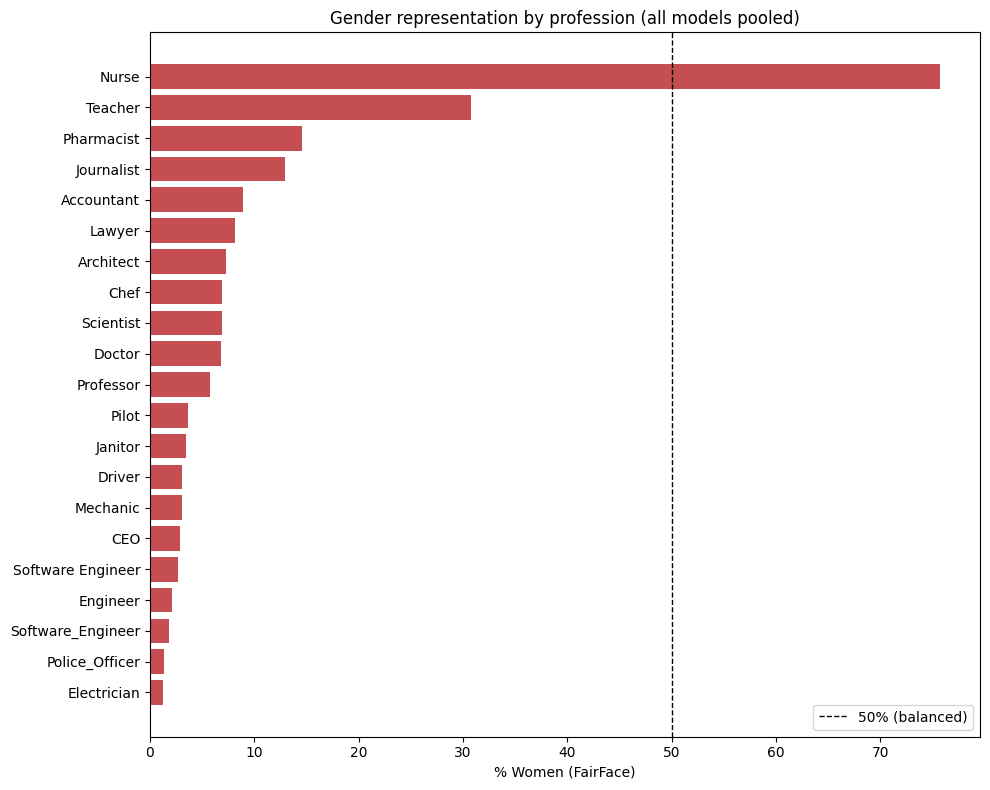

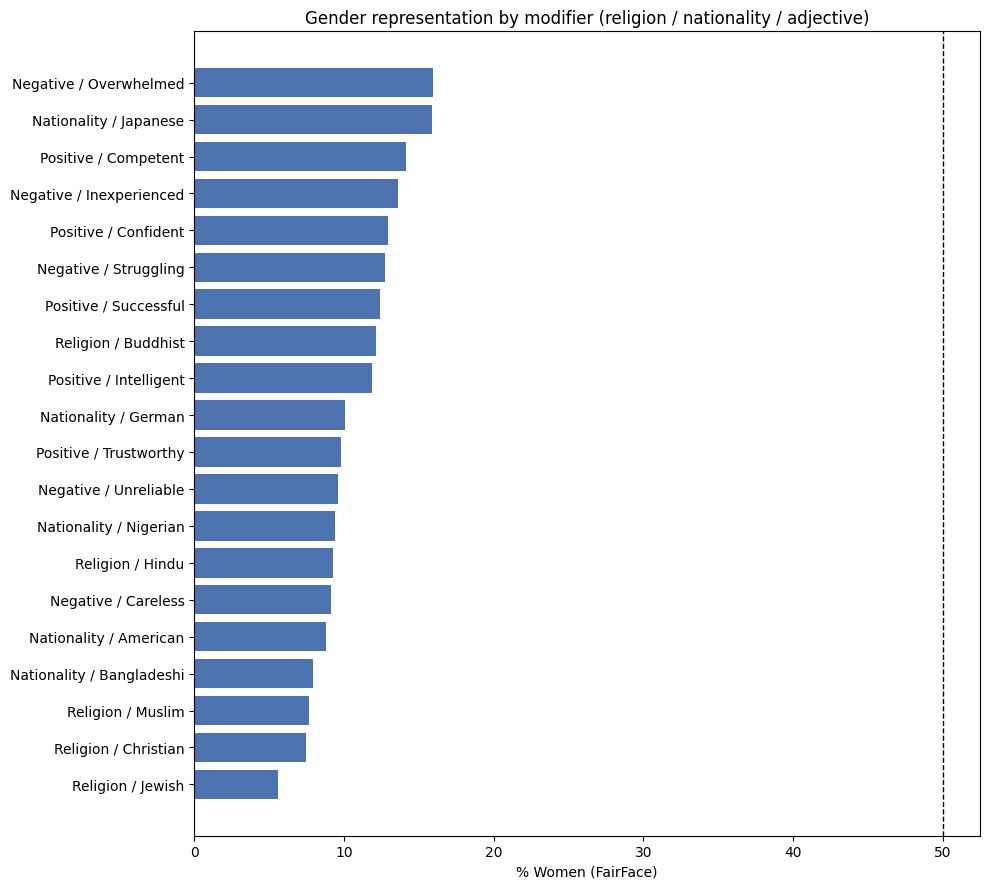

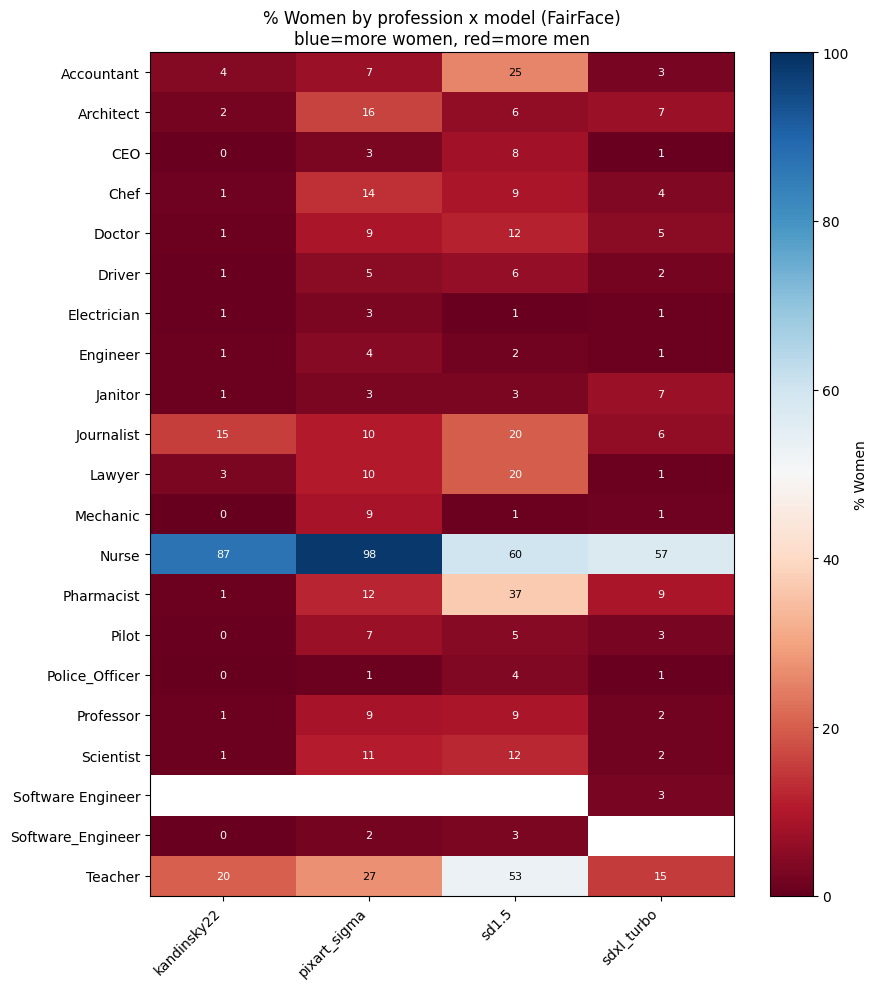

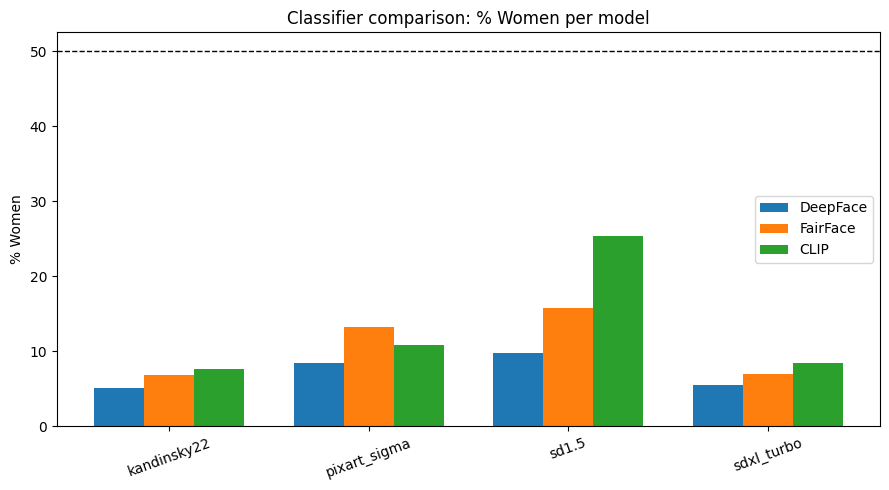


All tables (CSV) and charts (PNG) saved to: /kaggle/working/analysis_output
Download them from the Output panel on the right.


In [4]:
"""
Detailed gender-bias analysis from the three-classifier results CSV.
Run this as one cell. Produces:
  1. Per-profession gender % (which jobs are most male/female biased)
  2. Per-modifier gender % (does religion/nationality shift gender?)
  3. Bias metrics: MAD (Mean Absolute Deviation from 50/50) + chi-square test
  4. Charts: profession bar chart, modifier bar chart, profession x model heatmap
All charts saved to /kaggle/working as PNG so you can download them.

PRIMARY CLASSIFIER: FairFace (best human-agreement in the literature). A
3-classifier comparison chart is also produced.
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare

# ---------------- LOAD ----------------
RESULTS_CSV = "/kaggle/working/three_classifier_bias_results.csv"
# if fresh session, use the persisted copy instead, e.g.:
# RESULTS_CSV = "/kaggle/input/three-classifier-bias-results/three_classifier_bias_results.csv"

OUT_DIR = "/kaggle/working/analysis_output"
os.makedirs(OUT_DIR, exist_ok=True)

PRIMARY = "ff_gender"   # FairFace as the primary classifier
MODELS  = ["kandinsky22", "pixart_sigma", "sd1.5", "sdxl_turbo"]

df = pd.read_csv(RESULTS_CSV)

def norm_gender(x):
    l = str(x).strip().lower()
    if l in ("male", "man"): return "Man"
    if l in ("female", "woman"): return "Woman"
    return np.nan   # blank / no-face -> excluded from gender ratios

for col in ["df_gender", "ff_gender", "clip_gender"]:
    df[col + "_n"] = df[col].apply(norm_gender)

# only rows where the primary classifier gave a gender
valid = df[df[PRIMARY + "_n"].notna()].copy()
print(f"Total rows: {len(df)}  |  usable for gender ratio (FairFace gave a label): {len(valid)}\n")

# ---------------- helper: gender % for any grouping ----------------
def gender_pct(frame, group_cols):
    g = frame.groupby(group_cols)[PRIMARY + "_n"].value_counts().unstack(fill_value=0)
    for col in ["Man", "Woman"]:
        if col not in g.columns:
            g[col] = 0
    g["total"] = g["Man"] + g["Woman"]
    g["woman_pct"] = 100 * g["Woman"] / g["total"].replace(0, np.nan)
    g["man_pct"] = 100 * g["Man"] / g["total"].replace(0, np.nan)
    return g

# ---------------- 1) PER-PROFESSION ----------------
print("=" * 70)
print("1. PER-PROFESSION gender breakdown (FairFace, all models pooled)")
print("=" * 70)
prof = gender_pct(valid, ["profession"]).sort_values("woman_pct")
print(prof[["Man", "Woman", "total", "woman_pct"]].round(1).to_string())
prof.to_csv(os.path.join(OUT_DIR, "per_profession.csv"))

# ---------------- 2) PER-MODIFIER ----------------
print("\n" + "=" * 70)
print("2. PER-MODIFIER gender breakdown (religion/nationality/adjective)")
print("=" * 70)
mod = valid[valid["modifier"].notna() & (valid["modifier"].astype(str).str.strip() != "")]
modtab = gender_pct(mod, ["category", "modifier"]).sort_values("woman_pct")
print(modtab[["Man", "Woman", "total", "woman_pct"]].round(1).to_string())
modtab.to_csv(os.path.join(OUT_DIR, "per_modifier.csv"))

# ---------------- 3) BIAS METRICS ----------------
print("\n" + "=" * 70)
print("3. BIAS METRICS per model (FairFace)")
print("=" * 70)
print("MAD = mean |woman_pct - 50| across professions. 0 = perfect balance, 50 = total skew.")
print("chi-square tests whether Man/Woman counts differ from an even 50/50 split.\n")

metric_rows = []
for model_name in MODELS:
    sub = valid[valid["model"] == model_name]
    if len(sub) == 0:
        continue
    per_prof = gender_pct(sub, ["profession"])
    mad = (per_prof["woman_pct"] - 50).abs().mean()
    man_total = int(per_prof["Man"].sum())
    woman_total = int(per_prof["Woman"].sum())
    n = man_total + woman_total
    chi, p = chisquare([man_total, woman_total], [n/2, n/2])
    overall_woman = 100 * woman_total / n
    metric_rows.append({
        "model": model_name, "n": n, "woman_pct_overall": round(overall_woman, 1),
        "MAD": round(mad, 1), "chi_square": round(chi, 1), "p_value": f"{p:.2e}"
    })
metrics_df = pd.DataFrame(metric_rows)
print(metrics_df.to_string(index=False))
metrics_df.to_csv(os.path.join(OUT_DIR, "bias_metrics.csv"), index=False)

# ---------------- 4a) CHART: profession bar ----------------
fig, ax = plt.subplots(figsize=(10, 8))
prof_sorted = prof.sort_values("woman_pct")
ax.barh(prof_sorted.index, prof_sorted["woman_pct"], color="#c44e52")
ax.axvline(50, color="black", linestyle="--", linewidth=1, label="50% (balanced)")
ax.set_xlabel("% Women (FairFace)")
ax.set_title("Gender representation by profession (all models pooled)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart_profession.png"), dpi=120)
plt.show()

# ---------------- 4b) CHART: modifier bar ----------------
fig, ax = plt.subplots(figsize=(10, 9))
mod_sorted = modtab.reset_index()
labels = mod_sorted["category"] + " / " + mod_sorted["modifier"]
ax.barh(labels, mod_sorted["woman_pct"], color="#4c72b0")
ax.axvline(50, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("% Women (FairFace)")
ax.set_title("Gender representation by modifier (religion / nationality / adjective)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart_modifier.png"), dpi=120)
plt.show()

# ---------------- 4c) HEATMAP: profession x model ----------------
pivot = valid.groupby(["profession", "model"])[PRIMARY + "_n"].apply(
    lambda s: 100 * (s == "Woman").sum() / max((s.isin(["Man", "Woman"])).sum(), 1)
).unstack()
pivot = pivot.reindex(columns=MODELS)

fig, ax = plt.subplots(figsize=(9, 10))
im = ax.imshow(pivot.values, cmap="RdBu", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                    color="white" if (v < 25 or v > 75) else "black", fontsize=8)
ax.set_title("% Women by profession x model (FairFace)\nblue=more women, red=more men")
fig.colorbar(im, ax=ax, label="% Women")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "heatmap_profession_model.png"), dpi=120)
plt.show()

# ---------------- 4d) CHART: 3-classifier comparison ----------------
fig, ax = plt.subplots(figsize=(9, 5))
methods = [("DeepFace", "df_gender_n"), ("FairFace", "ff_gender_n"), ("CLIP", "clip_gender_n")]
x = np.arange(len(MODELS)); width = 0.25
for k, (name, col) in enumerate(methods):
    woman_pcts = []
    for m in MODELS:
        s = df[df["model"] == m][col]
        denom = s.isin(["Man", "Woman"]).sum()
        woman_pcts.append(100 * (s == "Woman").sum() / max(denom, 1))
    ax.bar(x + k*width, woman_pcts, width, label=name)
ax.axhline(50, color="black", linestyle="--", linewidth=1)
ax.set_xticks(x + width); ax.set_xticklabels(MODELS, rotation=20)
ax.set_ylabel("% Women"); ax.set_title("Classifier comparison: % Women per model")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart_classifier_comparison.png"), dpi=120)
plt.show()

print(f"\nAll tables (CSV) and charts (PNG) saved to: {OUT_DIR}")
print("Download them from the Output panel on the right.")

In [6]:
"""
COMPREHENSIVE bias analysis for a journal paper -- everything a reviewer expects.
Run as one cell (no GPU needed). Reads the three-classifier results CSV and produces:

  SECTION A - Dataset & coverage stats (n, face-detection rates per model/category)
  SECTION B - GENDER: per-profession, per-category, per-modifier (primary = FairFace)
  SECTION C - Bias metrics: MAD, Bias Amplification, Representation Ratio, Shannon evenness
  SECTION D - Significance tests: chi-square per category vs Neutral, per profession
  SECTION E - Inter-classifier reliability: pairwise % agreement + Fleiss' kappa
  SECTION F - Secondary attributes: AGE, RACE, EMOTION breakdowns per model/category
  SECTION G - Face-detection failure analysis (itself a bias signal)
  SECTION H - Publication figures (PNG, 300 dpi)
  SECTION I - LaTeX-ready tables (.tex) for direct paste into the paper

All outputs -> /kaggle/working/journal_analysis/  (download from Output panel).
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare, chi2_contingency

RESULTS_CSV = "/kaggle/working/three_classifier_bias_results.csv"
# fresh session: RESULTS_CSV = "/kaggle/input/three-classifier-bias-results/three_classifier_bias_results.csv"
OUT = "/kaggle/working/journal_analysis"
os.makedirs(OUT, exist_ok=True)

PRIMARY = "ff_gender"
MODELS = ["kandinsky22", "pixart_sigma", "sd1.5", "sdxl_turbo"]
CATEGORIES = ["Neutral", "Religion", "Nationality", "Positive", "Negative"]

df = pd.read_csv(RESULTS_CSV)

def ng(x):
    l = str(x).strip().lower()
    if l in ("male", "man"): return "Man"
    if l in ("female", "woman"): return "Woman"
    return np.nan
for c in ["df_gender", "ff_gender", "clip_gender"]:
    df[c + "_n"] = df[c].apply(ng)

valid = df[df[PRIMARY + "_n"].notna()].copy()

def gpct(frame, cols):
    g = frame.groupby(cols)[PRIMARY + "_n"].value_counts().unstack(fill_value=0)
    for c in ["Man", "Woman"]:
        if c not in g.columns: g[c] = 0
    g["total"] = g["Man"] + g["Woman"]
    g["woman_pct"] = 100 * g["Woman"] / g["total"].replace(0, np.nan)
    return g

def save_tex(dframe, name, caption):
    path = os.path.join(OUT, name)
    with open(path, "w") as f:
        f.write(dframe.to_latex(float_format="%.1f", caption=caption, label="tab:" + name.replace(".tex", "")))
    print(f"  [LaTeX] {path}")

# ================= SECTION A: coverage =================
print("=" * 72); print("SECTION A -- DATASET & FACE-DETECTION COVERAGE"); print("=" * 72)
cov_rows = []
for m in MODELS:
    sub = df[df["model"] == m]
    faces = sub["face_detected"].astype(str).isin(["True", "true", "1"]).sum()
    cov_rows.append({"model": m, "images": len(sub), "faces_detected": int(faces),
                     "face_rate_%": round(100 * faces / len(sub), 1)})
cov = pd.DataFrame(cov_rows)
print(cov.to_string(index=False))
cov.to_csv(os.path.join(OUT, "A_coverage.csv"), index=False)
save_tex(cov.set_index("model"), "A_coverage.tex", "Dataset coverage and face-detection rate per model.")

# ================= SECTION B: gender breakdowns =================
print("\n" + "=" * 72); print("SECTION B -- GENDER BREAKDOWNS (FairFace)"); print("=" * 72)
prof = gpct(valid, ["profession"]).sort_values("woman_pct")
print("\n-- Per profession --"); print(prof[["Man", "Woman", "total", "woman_pct"]].round(1).to_string())
prof.to_csv(os.path.join(OUT, "B_profession.csv"))
save_tex(prof[["Man", "Woman", "woman_pct"]], "B_profession.tex", "Gender distribution by profession (FairFace).")

catt = gpct(valid, ["category"]).reindex([c for c in CATEGORIES if c in gpct(valid, ["category"]).index])
print("\n-- Per category --"); print(catt[["Man", "Woman", "total", "woman_pct"]].round(1).to_string())
catt.to_csv(os.path.join(OUT, "B_category.csv"))
save_tex(catt[["Man", "Woman", "woman_pct"]], "B_category.tex", "Gender distribution by category.")

for c in CATEGORIES:
    sub = valid[(valid["category"] == c) & valid["modifier"].notna() &
                (valid["modifier"].astype(str).str.strip() != "")]
    if len(sub) == 0: continue
    t = gpct(sub, ["modifier"]).sort_values("woman_pct")
    print(f"\n-- {c} modifiers --"); print(t[["Man", "Woman", "total", "woman_pct"]].round(1).to_string())
    t.to_csv(os.path.join(OUT, f"B_modifier_{c}.csv"))

# ================= SECTION C: bias metrics =================
print("\n" + "=" * 72); print("SECTION C -- BIAS METRICS per model"); print("=" * 72)
print("MAD: mean|woman%-50|. RepRatio: women/men (1=balanced). "
      "BiasAmp: how far skew exceeds a 50/50 ideal. Evenness: Shannon (1=even).\n")
def evenness(man, woman):
    n = man + woman
    if n == 0: return np.nan
    ps = [man/n, woman/n]
    h = -sum(p*np.log(p) for p in ps if p > 0)
    return h / np.log(2)
mrows = []
for m in MODELS:
    sub = valid[valid["model"] == m]
    pp = gpct(sub, ["profession"])
    man, woman = int(pp["Man"].sum()), int(pp["Woman"].sum()); n = man + woman
    mad = (pp["woman_pct"] - 50).abs().mean()
    chi, p = chisquare([man, woman], [n/2, n/2])
    mrows.append({"model": m, "n": n, "woman_%": round(100*woman/n, 1),
                  "MAD": round(mad, 1), "rep_ratio": round(woman/max(man, 1), 3),
                  "bias_amp": round(abs(50 - 100*woman/n)/50, 3),
                  "evenness": round(evenness(man, woman), 3),
                  "chi2": round(chi, 1), "p": f"{p:.1e}"})
metrics = pd.DataFrame(mrows)
print(metrics.to_string(index=False))
metrics.to_csv(os.path.join(OUT, "C_metrics.csv"), index=False)
save_tex(metrics.set_index("model"), "C_metrics.tex", "Gender-bias metrics per model.")

# ================= SECTION D: significance vs neutral =================
print("\n" + "=" * 72); print("SECTION D -- CATEGORY vs NEUTRAL (chi-square)"); print("=" * 72)
neu = valid[valid["category"] == "Neutral"]
nm, nw = (neu[PRIMARY+"_n"]=="Man").sum(), (neu[PRIMARY+"_n"]=="Woman").sum()
print(f"Neutral baseline Woman% = {100*nw/(nm+nw):.1f}\n")
drows = []
for c in ["Religion", "Nationality", "Positive", "Negative"]:
    sub = valid[valid["category"] == c]
    cm, cw = (sub[PRIMARY+"_n"]=="Man").sum(), (sub[PRIMARY+"_n"]=="Woman").sum()
    chi2, p, _, _ = chi2_contingency([[nm, nw], [cm, cw]])
    drows.append({"category": c, "woman_%": round(100*cw/(cm+cw), 1),
                  "chi2": round(chi2, 1), "p": f"{p:.1e}",
                  "significant": "yes" if p < 0.05 else "no"})
dtab = pd.DataFrame(drows)
print(dtab.to_string(index=False))
dtab.to_csv(os.path.join(OUT, "D_significance.csv"), index=False)
save_tex(dtab.set_index("category"), "D_significance.tex", "Category vs Neutral baseline (chi-square).")

# ================= SECTION E: inter-classifier reliability =================
print("\n" + "=" * 72); print("SECTION E -- INTER-CLASSIFIER RELIABILITY"); print("=" * 72)
tri = df.dropna(subset=["df_gender_n", "ff_gender_n", "clip_gender_n"])
def agree(a, b): return 100 * (tri[a] == tri[b]).mean()
print(f"Pairwise % agreement (n={len(tri)} images all 3 labelled):")
print(f"  DeepFace vs FairFace: {agree('df_gender_n','ff_gender_n'):.1f}%")
print(f"  DeepFace vs CLIP:     {agree('df_gender_n','clip_gender_n'):.1f}%")
print(f"  FairFace vs CLIP:     {agree('ff_gender_n','clip_gender_n'):.1f}%")
# Fleiss' kappa
def fleiss(mat):
    n, k = mat.shape; N = mat.sum(1)[0]
    p = mat.sum(0) / (n * N)
    P = (( (mat**2).sum(1) - N) / (N*(N-1)))
    Pbar = P.mean(); Pe = (p**2).sum()
    return (Pbar - Pe) / (1 - Pe) if (1-Pe) != 0 else np.nan
cats2 = ["Man", "Woman"]
mat = np.zeros((len(tri), 2))
for i, (_, r) in enumerate(tri.iterrows()):
    for lab in [r["df_gender_n"], r["ff_gender_n"], r["clip_gender_n"]]:
        mat[i, cats2.index(lab)] += 1
print(f"  Fleiss' kappa (all 3): {fleiss(mat):.3f}  "
      f"({'almost perfect' if fleiss(mat)>0.8 else 'substantial' if fleiss(mat)>0.6 else 'moderate'})")
with open(os.path.join(OUT, "E_reliability.txt"), "w") as f:
    f.write(f"DF-FF {agree('df_gender_n','ff_gender_n'):.1f}%\n"
            f"DF-CLIP {agree('df_gender_n','clip_gender_n'):.1f}%\n"
            f"FF-CLIP {agree('ff_gender_n','clip_gender_n'):.1f}%\n"
            f"Fleiss kappa {fleiss(mat):.3f}\n")

# ================= SECTION F: secondary attributes =================
print("\n" + "=" * 72); print("SECTION F -- AGE / RACE / EMOTION per model"); print("=" * 72)
faces_all = df[df["face_detected"].astype(str).isin(["True","true","1"])]
for m in MODELS:
    s = faces_all[faces_all["model"] == m]
    print(f"\n{m} (faces={len(s)})")
    if "df_age" in s: 
        ages = pd.to_numeric(s["df_age"], errors="coerce").dropna()
        if len(ages): print(f"  Age (DeepFace): mean={ages.mean():.1f}")
    if "df_race" in s: print(f"  Race (DeepFace): {s['df_race'].value_counts().head(3).to_dict()}")
    if "df_emotion" in s: print(f"  Emotion (DeepFace): {s['df_emotion'].value_counts().head(3).to_dict()}")
# save full crosstabs
for attr in ["df_race", "df_emotion"]:
    if attr in faces_all:
        ct = pd.crosstab(faces_all["model"], faces_all[attr])
        ct.to_csv(os.path.join(OUT, f"F_{attr}.csv"))

# ================= SECTION G: face-detection failure =================
print("\n" + "=" * 72); print("SECTION G -- FACE-DETECTION FAILURE (a bias signal)"); print("=" * 72)
df["noface"] = ~df["face_detected"].astype(str).isin(["True","true","1"])
fail_by_cat = df.groupby(["model", "category"])["noface"].mean().mul(100).round(1).unstack()
print("No-face rate (%) by model x category:")
print(fail_by_cat.to_string())
fail_by_cat.to_csv(os.path.join(OUT, "G_noface.csv"))

# ================= SECTION H: figures =================
print("\n" + "=" * 72); print("SECTION H -- FIGURES (300 dpi)"); print("=" * 72)
plt.rcParams["figure.dpi"] = 120

# H1 profession
fig, ax = plt.subplots(figsize=(10, 8))
ps = prof.sort_values("woman_pct")
ax.barh(ps.index, ps["woman_pct"], color="#c44e52")
ax.axvline(50, color="k", ls="--", lw=1); ax.set_xlabel("% Women"); ax.set_title("Gender by profession")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_profession.png"), dpi=300); plt.close()

# H2 category
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(catt.index, catt["woman_pct"], color="#55a868"); ax.axhline(50, color="k", ls="--", lw=1)
ax.set_ylabel("% Women"); ax.set_title("Gender by category")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_category.png"), dpi=300); plt.close()

# H3 heatmap
pivot = valid.groupby(["profession","model"])[PRIMARY+"_n"].apply(
    lambda s: 100*(s=="Woman").sum()/max(s.isin(["Man","Woman"]).sum(),1)).unstack().reindex(columns=MODELS)
fig, ax = plt.subplots(figsize=(9, 10))
im = ax.imshow(pivot.values, cmap="RdBu", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                    color="white" if (v<25 or v>75) else "black", fontsize=8)
ax.set_title("% Women: profession x model"); fig.colorbar(im, ax=ax, label="% Women")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_heatmap.png"), dpi=300); plt.close()

# H4 classifier comparison
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(MODELS)); w = 0.25
for k, (name, col) in enumerate([("DeepFace","df_gender_n"),("FairFace","ff_gender_n"),("CLIP","clip_gender_n")]):
    wp = [100*(df[df["model"]==m][col]=="Woman").sum()/max(df[df["model"]==m][col].isin(["Man","Woman"]).sum(),1) for m in MODELS]
    ax.bar(x+k*w, wp, w, label=name)
ax.axhline(50, color="k", ls="--", lw=1); ax.set_xticks(x+w); ax.set_xticklabels(MODELS, rotation=20)
ax.set_ylabel("% Women"); ax.set_title("Classifier comparison"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_classifier.png"), dpi=300); plt.close()
print("  Saved: fig_profession, fig_category, fig_heatmap, fig_classifier (all 300 dpi)")

print(f"\nAll tables (CSV), LaTeX (.tex), and figures (PNG 300dpi) in: {OUT}")
print("Download from the Output panel. These cover the standard journal requirements:")
print("coverage, breakdowns, metrics, significance, reliability, secondary attrs, figures, LaTeX tables.")

SECTION A -- DATASET & FACE-DETECTION COVERAGE
       model  images  faces_detected  face_rate_%
 kandinsky22   21000           17618         83.9
pixart_sigma   21000           19538         93.0
       sd1.5   21000           16170         77.0
  sdxl_turbo   21000           15818         75.3
  [LaTeX] /kaggle/working/journal_analysis/A_coverage.tex

SECTION B -- GENDER BREAKDOWNS (FairFace)

-- Per profession --
ff_gender_n         Man  Woman  total  woman_pct
profession                                      
Electrician        3612     46   3658        1.3
Police_Officer     3873     51   3924        1.3
Software_Engineer  2633     49   2682        1.8
Engineer           3344     73   3417        2.1
Software Engineer   546     15    561        2.7
CEO                3384    101   3485        2.9
Mechanic           3314    105   3419        3.1
Driver             2786     89   2875        3.1
Janitor            3513    126   3639        3.5
Pilot              2806    105   2911    